# MuSiQue · Prolog instead of ONA (ablation, local)

Is it NARS that makes the difference, or would any logic engine do? This notebook takes the saved NARS runs
(`results/traces/<NARS system>/`) and gives **exactly the same triples and rule sets** to SWI-Prolog instead of ONA:
same questions, same k, same facts, same rules, same voting over rule sets. Only the reasoner changes. No new LLM
calls (only the judge grades answers that are not exact, a few cents).

What Prolog does not have, by design: truth values, preferring the answer type the question asks for, partial
matching. It proves a binding or it does not (details at the top of `common/prolog.py`).

**Needs:** SWI-Prolog (`brew install swi-prolog`), and the NARS traces from Colab copied into `results/traces/`.
Answers go to `results/answers/<Prolog system>/k<k>.jsonl`, so the report shows them next to every other system.

In [2]:
import json, os, subprocess, sys
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
sys.path.insert(0, "../common")
import experiment as ex
import prolog

DATASET = "MuSiQue"
N_QUESTIONS = 500             # the final run (questions.pkl must hold this many); 10 for a quick check
RESULTS = "results_final"     # the final question set; earlier runs stay in results/
SOURCE = "NARS + 8B + LoRA v2 final"   # whose triples and rules Prolog reuses
SYSTEM = "Prolog + 8B + LoRA v2 final"   # the name of this row in the results
K_VALUES = ex.K_VALUES[DATASET]
ex.SIZES.setdefault(SYSTEM, "8B")

print(subprocess.run([prolog.SWIPL, "--version"], capture_output=True, text=True).stdout.strip())
questions, question_hash = ex.load_questions("questions.pkl", N_QUESTIONS)
ex.guard(RESULTS, question_hash)
traces = {k: prolog.load_traces(RESULTS, SOURCE, k) for k in K_VALUES}
for k in K_VALUES:
    print(f"k={k:<2}: {len(traces[k])} {SOURCE} traces")
assert any(traces.values()), f"no traces for {SOURCE} in {RESULTS}/traces/: copy them from Colab first"

SWI-Prolog version 10.0.2 for arm64-darwin
k=0 : 200 NARS + 8B + LoRA traces
k=4 : 198 NARS + 8B + LoRA traces
k=8 : 199 NARS + 8B + LoRA traces
k=16: 200 NARS + 8B + LoRA traces


In [3]:
judge = ex.deepinfra()


def run_one(index, k):
    q, trace = questions[index], traces[k][index]
    answer, votes, errors = prolog.solve(trace)
    record = {"index": index, "id": q["id"], "source": q.get("source_split"), "question": q["question"],
              "gold": q["answer"], "golds": ex.golds(q), "k": k, "system": SYSTEM, "kind": "prolog",
              "model": f"SWI-Prolog over the rules of {SOURCE}", "answer": answer, "votes": votes,
              "nars_answer": trace.get("answer"), "prolog_errors": errors, "error": None, "cost": 0.0,
              "started": datetime.now(timezone.utc).isoformat()}
    try:
        record.update(ex.metrics(judge, q, answer))
    except Exception as error:
        record["error"] = f"{type(error).__name__}: {error}"
    return record


for k in K_VALUES:
    done = ex.load_answers(RESULTS, SYSTEM, k)
    todo = [i for i in sorted(traces[k]) if i < len(questions) and i not in done]
    path = ex.answers_path(RESULTS, SYSTEM, k)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with ThreadPoolExecutor(8) as pool, open(path, "a") as f:
        for record in pool.map(lambda i: run_one(i, k), todo):
            f.write(json.dumps(record, ensure_ascii=False) + "\n")
    saved = ex.load_answers(RESULTS, SYSTEM, k)
    right = sum(r["judge"] for r in saved.values())
    print(f"✔ {SYSTEM} k={k:<2}: {right}/{len(saved)} judged correct ({100 * right / max(len(saved), 1):.1f}%) · "
          f"{len(todo)} run now")

✔ Prolog + 8B + LoRA k=0 : 92/200 judged correct (46.0%) · 200 run now
✔ Prolog + 8B + LoRA k=4 : 81/198 judged correct (40.9%) · 198 run now
✔ Prolog + 8B + LoRA k=8 : 73/199 judged correct (36.7%) · 199 run now
✔ Prolog + 8B + LoRA k=16: 74/200 judged correct (37.0%) · 200 run now


## Prolog vs ONA on the same triples and rules

In [4]:
from prettytable import PrettyTable

table = PrettyTable(["k", "questions", "ONA right", "Prolog right", "both", "only ONA", "only Prolog",
                     "ONA no answer", "Prolog no answer", "same answer"])
for k in K_VALUES:
    nars, pro = ex.load_answers(RESULTS, SOURCE, k), ex.load_answers(RESULTS, SYSTEM, k)
    common = sorted(nars.keys() & pro.keys())
    if not common:
        continue
    a = [nars[i]["judge"] for i in common]
    b = [pro[i]["judge"] for i in common]
    table.add_row([k, len(common), f"{100 * sum(a) / len(common):.1f}%", f"{100 * sum(b) / len(common):.1f}%",
                   sum(x and y for x, y in zip(a, b)), sum(x and not y for x, y in zip(a, b)),
                   sum(y and not x for x, y in zip(a, b)),
                   sum(not nars[i]["answer"] for i in common), sum(not pro[i]["answer"] for i in common),
                   sum(ex.normalize(nars[i]["answer"] or "") == ex.normalize(pro[i]["answer"] or "") for i in common)])
print(table)

+----+-----------+-----------+--------------+------+----------+-------------+---------------+------------------+-------------+
| k  | questions | ONA right | Prolog right | both | only ONA | only Prolog | ONA no answer | Prolog no answer | same answer |
+----+-----------+-----------+--------------+------+----------+-------------+---------------+------------------+-------------+
| 0  |    200    |   46.5%   |    46.0%     |  87  |    6     |      5      |       40      |        40        |     175     |
| 4  |    198    |   41.9%   |    40.9%     |  77  |    6     |      4      |       45      |        45        |     176     |
| 8  |    199    |   38.7%   |    36.7%     |  68  |    9     |      5      |       46      |        46        |     171     |
| 16 |    200    |   38.0%   |    37.0%     |  68  |    8     |      6      |       41      |        41        |     169     |
+----+-----------+-----------+--------------+------+----------+-------------+---------------+------------------

## Report (every system saved in results/)

MUSIQUE · 200 questions · 2394 answers · k = 0, 4, 8, 16

ACCURACY (%) · judge
+--------------------+------+------+------+------+------+--------+-----+
| System             | Size | k=0  | k=4  | k=8  | k=16 | Δ 0→16 |  n  |
+--------------------+------+------+------+------+------+--------+-----+
| Llama-3.1-8B       |  8B  | 65.5 | 59.0 | 52.5 | 45.5 | -20.0  | 200 |
| NARS + 8B + LoRA   |  8B  | 46.5 | 41.9 | 38.7 | 38.0 |  -8.5  | 200 |
| Prolog + 8B + LoRA |  8B  | 46.0 | 40.9 | 36.7 | 37.0 |  -9.0  | 200 |
+--------------------+------+------+------+------+------+--------+-----+

ACCURACY (%) · exact
+--------------------+------+------+------+------+------+--------+-----+
| System             | Size | k=0  | k=4  | k=8  | k=16 | Δ 0→16 |  n  |
+--------------------+------+------+------+------+------+--------+-----+
| Llama-3.1-8B       |  8B  | 48.5 | 44.0 | 35.5 | 27.5 | -21.0  | 200 |
| NARS + 8B + LoRA   |  8B  | 33.0 | 29.8 | 27.1 | 28.5 |  -4.5  | 200 |
| Prolog + 8B + LoRA | 

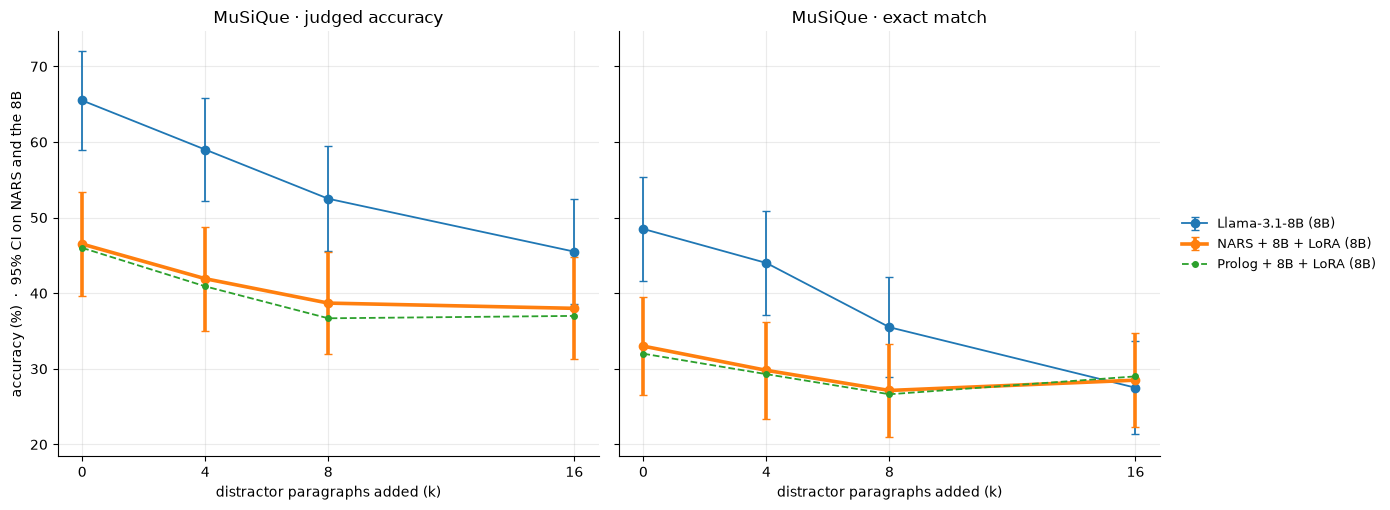

saved results/report.txt and results/accuracy_vs_k.png


In [5]:
ex.report(RESULTS, DATASET, N_QUESTIONS)